# Decision Trees

## An indoor ride or an outdoor ride?

A park visitor's choice can depend on both temperature and the rain forecast. In these synthetic records, hotter or rainier conditions often accompany an indoor choice, with some exceptions. The inputs are temperature in degrees Celsius and rain probability as a percentage. The label is the visitor's recorded indoor or outdoor choice.

A decision tree asks a sequence of questions about input features. Each split sends a record down one of two branches. A leaf stores the class proportions among training records that reach it; the most common class becomes its prediction.

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/04_tree_splits.png" alt="A tree fitted to the park records uses actual weather thresholds to route visits to indoor or outdoor predictions." width="640" style="max-width:100%;height:auto;">

Gini impurity measures how mixed the class labels are within a node. It is zero when all records have the same label. The algorithm compares candidate thresholds and chooses a split that reduces the children’s impurity, weighted by how many training records enter each child. It repeats this process until a stopping rule is reached.


## More branches, more detailed regions

The depth control limits how many splits can occur along a path. A shallow tree may miss a useful pattern and underfit. A deeper tree can isolate individual exceptions and overfit. Each background region is a leaf prediction from the selected tree.

The temperature and rain controls describe a new visit. The star and the predicted choice use those same inputs. Colored points are validation visits; they are never used to choose a split. Training and validation accuracy reveal whether extra depth helps beyond the fitting records.

`Validation best` selects the highest validation accuracy among five predefined depth limits. A tie favors the shallower tree. Moving the controls does not change that candidate list. This selection uses validation data, so its score is not a final test result.


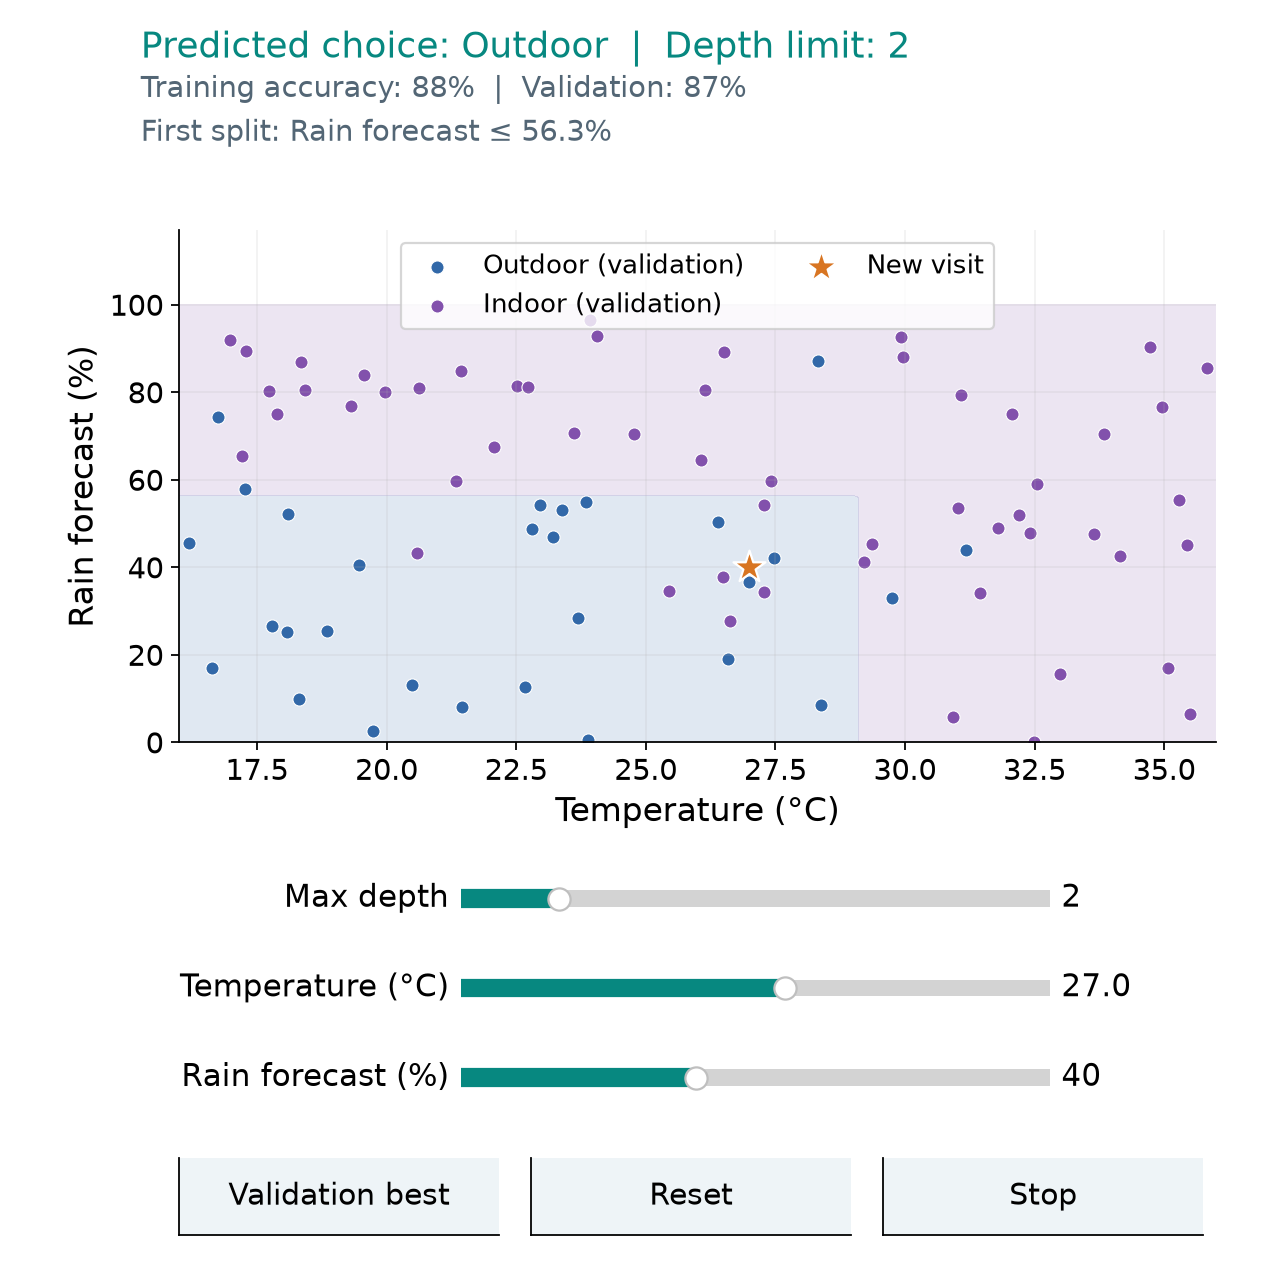

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 15, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    # The logaddexp form avoids taking log(0) at extreme scores.
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


# A rerun releases the previous figure and its input callbacks first.
for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:
    """One figure keeps the selected model, predictions and scores together."""

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            self.figure = plt.figure(figsize=(8, 8.0 if len(sliders) == 3 else 7.4), dpi=80)
        self.status = self.figure.text(.11, .955, "", fontsize=16, color=TEAL)
        self.detail = self.figure.text(.11, .89, "", fontsize=13, color="#536675", linespacing=1.5)
        bottom = .28 + .07 * (len(sliders) - 1)
        self.ax = self.figure.add_axes([.14, bottom, .81, .82 - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = .145 + .07 * (len(sliders) - i - 1)
            slider = Slider(self.figure.add_axes([.36, y, .46, .026]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(14)
            slider.valtext.set_fontsize(14)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .83 / len(commands) - .025)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.14 + i * (width + .025), .035, width, .06]),
                            label, color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(13.5)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        # Crop only the embedded Matplotlib controls; native widgets follow the chart.
        lower = max(0, self.ax.get_position().y0 - .09) * height
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=80, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="640px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "120px"},
                                  layout=Layout(width="100%", max_width="640px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="640px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=640,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            # JSPCV sends mouse events after this cell has returned.
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            # The ipympl figure supplies a responsive chart with native widget controls.
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()

rng = np.random.default_rng(72)
weather = np.column_stack([rng.uniform(16, 36, 240), rng.uniform(0, 100, 240)])
indoor = ((weather[:, 0] > 29) | (weather[:, 1] > 55)).astype(int)
flips = rng.random(len(indoor)) < .13
indoor[flips] = 1 - indoor[flips]
train_id, validation_id = train_test_split(np.arange(len(indoor)), test_size=.35,
                                         stratify=indoor, random_state=72)
tree_models = {depth: DecisionTreeClassifier(max_depth=depth, random_state=72).fit(
    weather[train_id], indoor[train_id]) for depth in range(1, 8)}
candidate_depths = (1, 2, 3, 5, 7)
validation_scores = {depth: model.score(weather[validation_id], indoor[validation_id])
                     for depth, model in tree_models.items()}
# Ties favor the shallower model; slider changes do not alter the candidate set.
best_depth = max(candidate_depths, key=lambda depth: (validation_scores[depth], -depth))
temperature_grid, rain_grid = np.meshgrid(np.linspace(16, 36, 101), np.linspace(0, 100, 101))
weather_grid = np.c_[temperature_grid.ravel(), rain_grid.ravel()]
region_cache = {depth: model.predict(weather_grid).reshape(temperature_grid.shape)
                for depth, model in tree_models.items()}


def render_park(view, depth, temperature, rain):
    model = tree_models[int(depth)]
    query = np.array([[temperature, rain]])
    predicted = int(model.predict(query)[0])
    probability = model.predict_proba(query)[0]
    train_accuracy = model.score(weather[train_id], indoor[train_id])
    ax = view.ax
    ax.contourf(temperature_grid, rain_grid, region_cache[int(depth)], levels=[-.5, .5, 1.5],
                colors=[BLUE, PURPLE], alpha=.15)
    for value, color, label in [(0, BLUE, "Outdoor"), (1, PURPLE, "Indoor")]:
        selected = validation_id[indoor[validation_id] == value]
        ax.scatter(weather[selected, 0], weather[selected, 1], color=color, s=35,
                   edgecolor="white", linewidth=.5, label=label + " (validation)")
    ax.scatter([temperature], [rain], s=230, marker="*", color=ORANGE,
               edgecolor="white", linewidth=1, label="New visit", zorder=5)
    ax.set(xlim=(16, 36), ylim=(0, 117), xlabel="Temperature (°C)", ylabel="Rain forecast (%)")
    ax.legend(loc="upper center", ncol=2, fontsize=11.5)
    root_feature = ["Temperature", "Rain forecast"][model.tree_.feature[0]]
    root_unit = ["°C", "%"][model.tree_.feature[0]]
    label = ["Outdoor", "Indoor"][predicted]
    view.status.set_text(f"Predicted choice: {label}  |  Depth limit: {int(depth)}")
    view.detail.set_text(f"Training accuracy: {train_accuracy:.0%}  |  Validation: {validation_scores[int(depth)]:.0%}\n"
                         f"First split: {root_feature} ≤ {model.tree_.threshold[0]:.1f}{root_unit}")
    return {"prediction": predicted, "probability": probability, "model": model,
            "query": query, "train_accuracy": train_accuracy,
            "validation_accuracy": validation_scores[int(depth)]}


park_demo = ClassificationExplorer("park", render_park, [
    ("depth", "Max depth", 1, 7, 2, 1, "%0.0f"),
    ("temperature", "Temperature (°C)", 16, 36, 27, .5, "%0.1f"),
    ("rain", "Rain forecast (%)", 0, 100, 40, 1, "%0.0f"),
], actions=[("Validation best", lambda view: view.set_values(depth=best_depth))])
park_demo.start()


## A clear rule can still be fragile

Each split uses one feature, so this tree forms rectangular regions. Tree depth and minimum leaf size can limit complexity. A small data change can still move a threshold or select a different branch.

The splits describe associations in these records, not the effect of changing the weather. Personal preferences and ride closures are absent. More branches cannot recover missing information reliably, and a separate test set is needed after choosing the depth.
